# AE3GIS benchmarks: comparing the hosts

Every host ran the same two suites: idle capacity (`random`) and traffic limits (`traffic`). Each host's full report is in `hosts/<host>.ipynb`. This notebook puts the major metrics side by side.

Read the traffic numbers with the data-quality section (§6) in mind: not every host's traffic was measured with the same driver.

In [1]:
import warnings
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import pandas as pd

from benchlib import load, plots, random_suite as rs, traffic_suite as ts
from benchlib.hosts import HOSTS, REFERENCE

warnings.filterwarnings("ignore", category=RuntimeWarning)
plots.style()
pd.set_option("display.precision", 1)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)


def show(fig):
    if fig is not None:
        display(fig)
        plt.close(fig)

data = load.load_all()
H = list(data)
names = {k: data[k].host.name for k in H}

In [2]:
# Sanity checks against values known from the runs.
import math
known = {"m4-macbook-air": (530, 73), "m4max-studio-dd12-95g": (1884, 545), "microsoft-surface-7": (403, 42)}
for k, (m, s) in known.items():
    st = rs.ceiling_stats(data[k].random)
    assert round(st["mean"]) == m and round(st["std"]) == s, (k, st["mean"], st["std"])
cost_ref = {"m4-macbook-air": 1.9, "m4max-studio-dd12-95g": 1.0, "microsoft-surface-7": 4.7}
for k, v in cost_ref.items():
    got = ts.cost_by_size(data[k].traffic.rows).loc["mesh·udp", "250–450"]
    assert math.isclose(got, v, rel_tol=0.15), (k, got)
print("checks passed")

checks passed


## 1. The hosts

In [3]:
rows = []
for k in H:
    d, h = data[k], data[k].host
    tr = d.traffic
    fixed = (tr.rows["driver"] == "fixed").mean() if len(tr.rows) else 0
    rows.append({
        "host": h.name, "machine": h.hardware, "OS": h.os, "Docker": h.docker,
        "Docker resources": h.resources, "cooling": h.cooling,
        "traffic cells final": f"{int(tr.cells['done'].sum())}/100",
        "traffic runs by the fixed driver": f"{fixed:.0%}",
        "settings off the defaults": len(h.deviations),
    })
display(pd.DataFrame(rows).set_index("host").T)

host,M4 MacBook Air,M4 Max Mac Studio,Surface Laptop 7
machine,"MacBook Air 15"" (Mac16,13), Apple M4 (4P + 6E cores), 32 GB","Mac Studio, Apple M4 Max (12P + 4E cores), 128 GB","Microsoft Surface Laptop 7, Intel Core Ultra 7 268V (8 cores), 32 GB"
OS,macOS 26.7.1,macOS (Darwin 24.6.0),Windows 11 (Docker on WSL2)
Docker,Docker Desktop 4.95.0 (Docker 29.8.2),"Docker Desktop 4.47.0 (Docker 28.4.0, then 29.8.2 from climb 4)",Docker Desktop 4.45.0 (Docker 28.3.3) on WSL2
Docker resources,8 CPUs / 16.7 GB,12 CPUs / 101.9 GB,8 CPUs / 16.6 GB
cooling,fanless,active,active
traffic cells final,90/100,100/100,100/100
traffic runs by the fixed driver,39%,0%,0%
settings off the defaults,0,1,1


## 2. Headline numbers

In [4]:
head = {}
for k in H:
    d = data[k]
    c = d.random.climbs
    carried1m = d.traffic.cells[d.traffic.cells["rate"] == "1M"].groupby("scenario")["carried_mbps"].median()
    cost = ts.cost_summary(d.traffic.rows)
    row = {
        "idle ceiling (hosts)": f"{c['ceiling'].mean():.0f} ± {c['ceiling'].std():.0f}",
        "idle hosts per GB": c["ceiling"].mean() / d.host.mem_gb,
        "MB per node": c["mb_per_node"].mean(),
        "deploy s per node": c["deploy_s_per_node"].mean(),
        "idle climbs stopped by": rs.climb_stops(d.random).value_counts().idxmax(),
    }
    for s in ts.SCENARIO_ORDER:
        row[f"Mb/s at 1M · {s}"] = carried1m.get(s)
    for s in ts.SCENARIO_ORDER:
        row[f"cores/100 Mb/s · {s}"] = cost.get(s)
    head[names[k]] = row
head = pd.DataFrame(head)
display(head.style.format(lambda v: f"{v:.2f}" if isinstance(v, float) and v < 10 else
                          (f"{v:.0f}" if isinstance(v, float) else v)))
ref = names[REFERENCE]
num = head.drop(index=["idle ceiling (hosts)", "idle climbs stopped by"]).astype(float)
num.loc["idle ceiling (mean)"] = [data[k].random.climbs["ceiling"].mean() for k in H]
display((num.div(num[ref], axis=0)).style.format("{:.2f}×").set_caption(f"Relative to the {ref}"))

,M4 MacBook Air,M4 Max Mac Studio,Surface Laptop 7
idle ceiling (hosts),530 ± 73,1884 ± 545,403 ± 42
idle hosts per GB,32,18,24
MB per node,23,27,24
deploy s per node,0.33,0.78,2.47
idle climbs stopped by,memory,deploy failed,memory
Mb/s at 1M · cs·tcp,50,100,50
Mb/s at 1M · cs·udp,100,150,50
Mb/s at 1M · mesh·tcp,200,600,200
Mb/s at 1M · mesh·udp,300,1000,300
cores/100 Mb/s · cs·tcp,8.33,6.06,14


,M4 MacBook Air,M4 Max Mac Studio,Surface Laptop 7
idle hosts per GB,1.00×,0.58×,0.76×
MB per node,1.00×,1.20×,1.06×
deploy s per node,1.00×,2.35×,7.46×
Mb/s at 1M · cs·tcp,1.00×,2.00×,1.00×
Mb/s at 1M · cs·udp,1.00×,1.50×,0.50×
Mb/s at 1M · mesh·tcp,1.00×,3.00×,1.00×
Mb/s at 1M · mesh·udp,1.00×,3.33×,1.00×
cores/100 Mb/s · cs·tcp,1.00×,0.73×,1.62×
cores/100 Mb/s · cs·udp,1.00×,0.77×,2.57×
cores/100 Mb/s · mesh·tcp,1.00×,0.56×,1.55×


## 3. Idle capacity

Bars show the mean ± std over all 10 climbs, and the dots show every climb; annotated climbs are grey. See each host's report for why they're annotated.
- The **Studio's** grey climbs ran on a broken Docker, so its mean mixes ~1160 with ~2290.
- The **Studio** is stopped by Docker Desktop's deploy wall, not by memory.

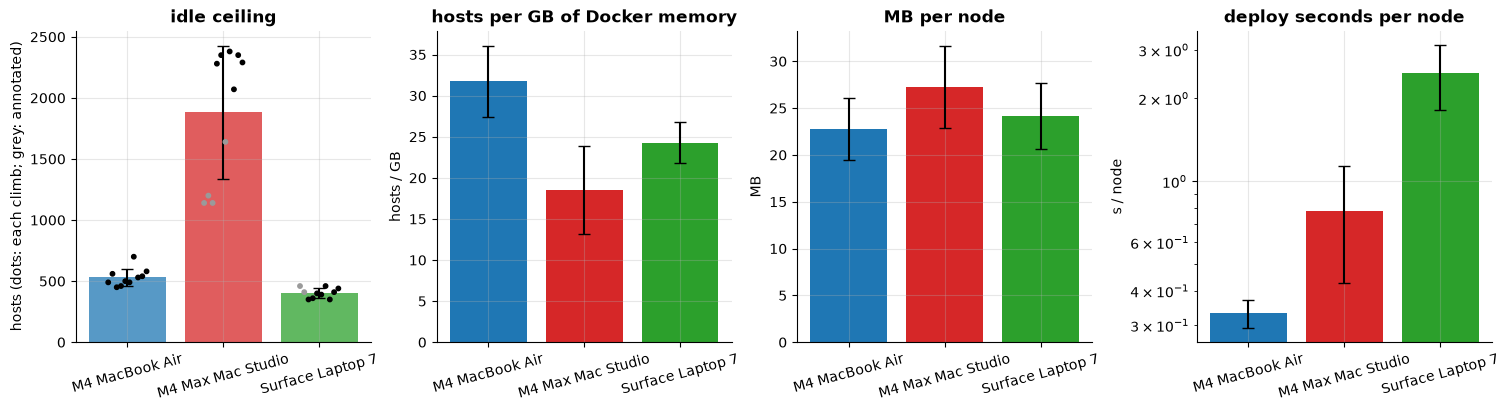

In [5]:
show(plots.idle_comparison(data))

## 4. Do the hosts measure images alike?

Each image's **container memory**, from every climb's ceiling (hundreds of containers per host), against the reference host. Points on the dashed line cost the same on both. The census's host memory per node is not used here: at 5 nodes per image it is mostly per-lab overhead for light images.

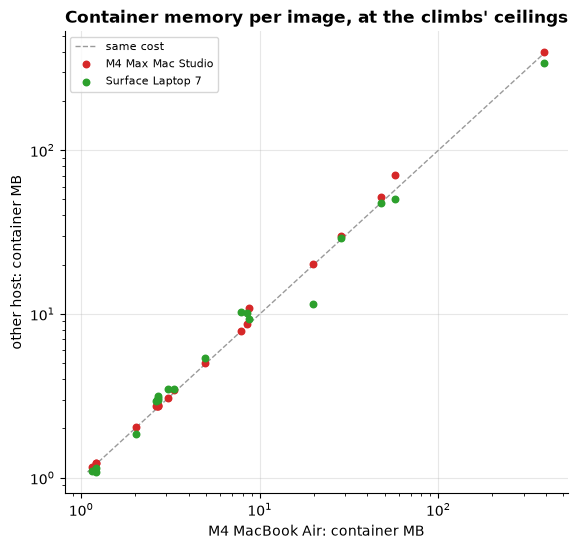

,M4 MacBook Air,M4 Max Mac Studio,Surface Laptop 7
median ratio to the reference,1.00×,1.02×,1.06×


,M4 MacBook Air,M4 Max Mac Studio,Surface Laptop 7
image,,,
ae3gis.local/nginx,8.7,10.9,9.4
ae3gis.local/open-vswitch,19.9,20.2,11.5
ae3gis.local/samba,7.8,7.9,10.2
ae3gis.local/suricata,57.4,71.0,50.4


In [6]:
im = pd.DataFrame({k: rs.image_memory(data[k].random) for k in H})
imn = im.rename(columns=names)
show(plots.census_agreement(im, REFERENCE, "Container memory per image, at the climbs' ceilings", unit="container MB"))
display(imn.div(imn[names[REFERENCE]], axis=0).median().rename("median ratio to the reference").to_frame().T.style.format("{:.2f}×"))
off = im.div(im[REFERENCE], axis=0)
off = off[(off - 1).abs().max(axis=1) > 0.2]
display(imn.loc[off.index].style.format("{:.1f}", na_rep="–").set_caption("Images more than 20% apart on some host (MB)"))

## 5. Traffic

### At high rates (1M / 500K / 250K per flow)

These rows compare directly: every host's labs are small enough here, and the caps don't apply.

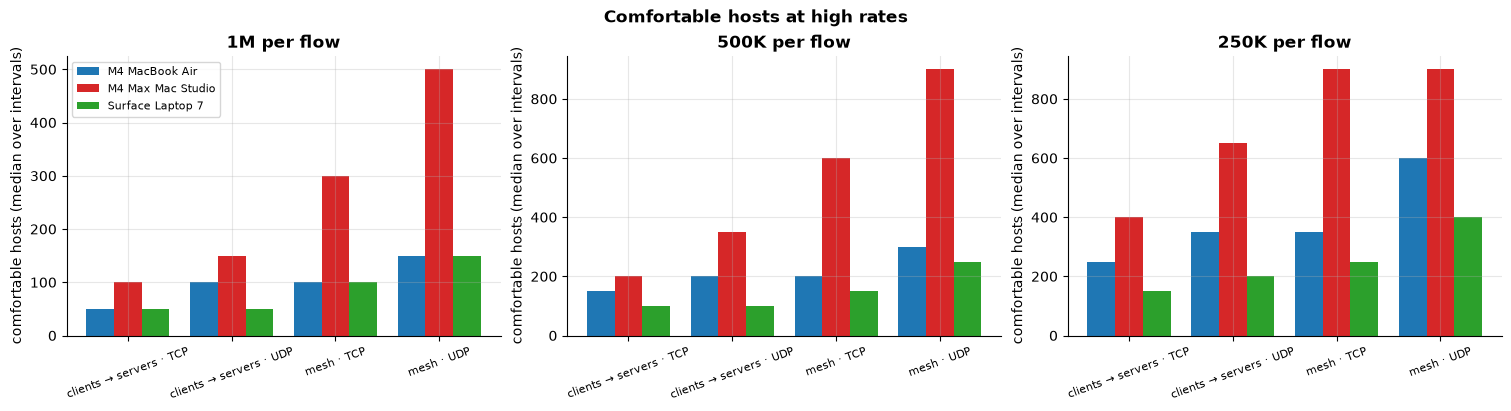

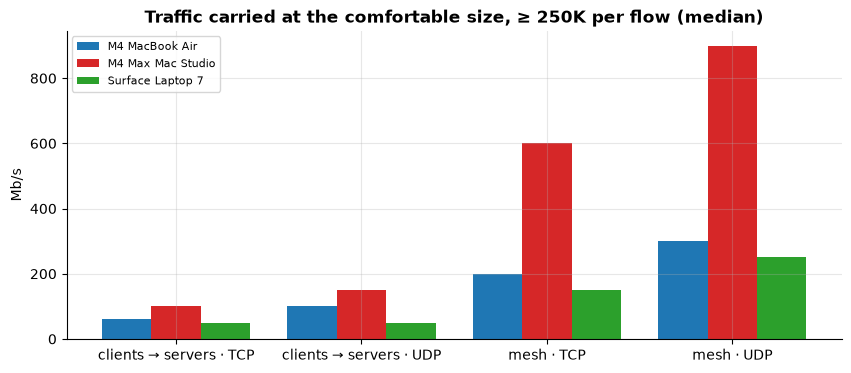

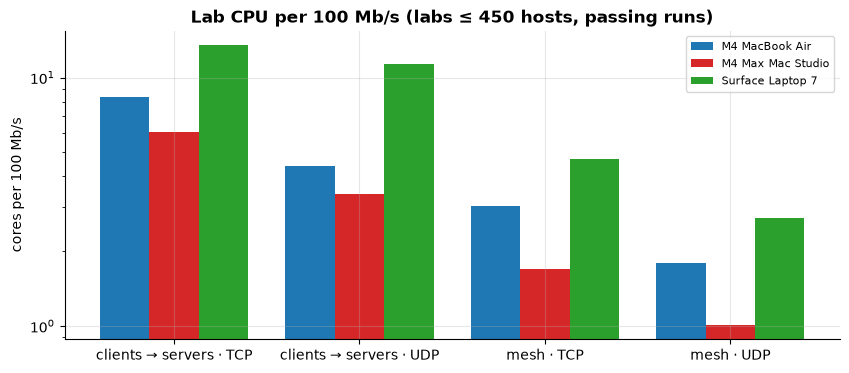

In [7]:
vals = {}
for rate in ("1M", "500K", "250K"):
    vals[rate] = pd.DataFrame({k: data[k].traffic.cells[data[k].traffic.cells["rate"] == rate]
                               .groupby("scenario")["comfortable"].median() for k in H}).reindex(ts.SCENARIO_ORDER)
show(plots.high_rate_comparison(vals, "Comfortable hosts at high rates"))
carried = pd.DataFrame({k: data[k].traffic.cells[data[k].traffic.cells["rate"].isin(["1M", "500K", "250K"])]
                        .groupby("scenario")["carried_mbps"].median() for k in H}).reindex(ts.SCENARIO_ORDER)
show(plots.host_bars(carried.rename(index=plots._scenario), "Traffic carried at the comfortable size, ≥ 250K per flow (median)",
                     "Mb/s"))
cost = pd.DataFrame({k: ts.cost_summary(data[k].traffic.rows) for k in H}).reindex(ts.SCENARIO_ORDER)
show(plots.host_bars(cost.rename(index=plots._scenario), "Lab CPU per 100 Mb/s (labs ≤ 450 hosts, passing runs)",
                     "cores per 100 Mb/s", log=True))

### At low rates (100K / 50K per flow)

A table rather than a chart: here the hosts hit different caps.
- **Surface:** its deploys stop it at 400 hosts.
- **Studio:** the search tops out at 1000.
- **Air:** open cells are marked `…`.

In [8]:
low = {}
for k in H:
    c = data[k].traffic.cells
    c = c[c["rate"].isin(["100K", "50K"])].copy()
    c["label"] = c.apply(ts.label, axis=1)
    for (s, rate), g in c.groupby(["scenario", "rate"]):
        low.setdefault((plots._scenario(s), rate), {})[names[k]] = " | ".join(g.sort_values("interval_ms")["label"])
display(pd.DataFrame(low).T.rename_axis(["scenario", "rate"]).style.set_caption(
    "comfortable / fails at, intervals 100 | 250 | 500 | 1000 | 2000 ms"))

## 6. Data quality: which numbers can be trusted how far

The old traffic driver (before 2026-10-12) started clients slowly and began the measured window at a fixed time. In big labs that meant partial load, clients that never started, and memory stalls. The Air was re-measured on the fixed driver; the Studio and the Surface were not.

Below, for mesh labs:
- the share of runs with dead flows, and the median full memory stalls, by host, driver and lab size. Under the fixed driver every client starts before the window, so dead flows there are a real overload (clients that couldn't connect), not a driver artifact;
- each host's CPU per 100 Mb/s across lab sizes. A falling line means partial load.

In [9]:
q = pd.concat({names[k]: ts.quality_by_size(data[k].traffic.rows, "mesh") for k in H})
display(q.style.format({"dead_flows_pct": "{:.0f}", "psi_mem_full_median": "{:.1f}", "mem_pct_median": "{:.0f}"}))
trend = pd.DataFrame({names[k]: ts.cost_by_size(data[k].traffic.rows).loc["mesh·udp"] for k in H}).T
display(trend.style.format("{:.2f}", na_rep="–").set_caption("mesh · UDP: cores per 100 Mb/s by lab size"))

bin,0–250,250–450,450–650,650–850,850–1100
M4 MacBook Air,1.68,1.87,2.01,2.31,2.08
M4 Max Mac Studio,–,1.05,0.94,0.86,0.97
Surface Laptop 7,2.47,4.65,–,–,–


## 7. Key takeaways

In [10]:
air, studio, surface = (data.get(k) for k in ("m4-macbook-air", "m4max-studio-dd12-95g", "microsoft-surface-7"))
def ceil(d): return d.random.climbs["ceiling"]
def at1m(d, s): return d.traffic.cells[(d.traffic.cells["rate"] == "1M") & (d.traffic.cells["scenario"] == s)]["carried_mbps"].median()
cs = {k: ts.cost_summary(data[k].traffic.rows) for k in H}
_ref = air.traffic.cells.set_index("cell")
_hr = _ref[_ref["rate"].isin(["1M", "500K", "250K"])].index
hr = {k: (data[k].traffic.cells.set_index("cell").loc[_hr, "comfortable"] / _ref.loc[_hr, "comfortable"]).median() for k in H}
lines = [
    f"- **Idle capacity:**",
    f"  - Air **{ceil(air).mean():.0f} ± {ceil(air).std():.0f}** and Surface **{ceil(surface).mean():.0f} ± {ceil(surface).std():.0f}** hosts, both stopped by memory at ~90% of a similar 16.6–16.7 GB. "
    f"The Air fits {ceil(air).mean() / ceil(surface).mean() - 1:.0%} more hosts, and the Surface pays more per node (WSL2) and deploys "
    f"{surface.random.climbs['deploy_s_per_node'].mean() / air.random.climbs['deploy_s_per_node'].mean():.0f}× slower per node.",
    f"  - Studio **{ceil(studio).mean():.0f} ± {ceil(studio).std():.0f}** over all climbs (clean climbs ~2290), stopped by Docker Desktop's deploy wall with memory at ~75%: its hardware isn't the limit.",
    f"- **Traffic at 1M per flow:**",
    f"  - clients → servers TCP carries {at1m(air, 'cs·tcp'):.0f} / {at1m(studio, 'cs·tcp'):.0f} / {at1m(surface, 'cs·tcp'):.0f} Mb/s (Air / Studio / Surface);",
    f"  - mesh UDP carries {at1m(air, 'mesh·udp'):.0f} / {at1m(studio, 'mesh·udp'):.0f} / {at1m(surface, 'mesh·udp'):.0f} Mb/s.",
    f"  Over every cell at ≥ 250K per flow, the Studio holds a median **{hr['m4max-studio-dd12-95g']:.1f}×** the Air's hosts and the Surface **{hr['microsoft-surface-7']:.2f}×**.",
    f"- **Why:** CPU per 100 Mb/s (mesh UDP) is {cs['m4max-studio-dd12-95g'].get('mesh·udp', float('nan')):.1f} on the Studio, {cs['m4-macbook-air'].get('mesh·udp', float('nan')):.1f} on the Air and "
    f"{cs['microsoft-surface-7'].get('mesh·udp', float('nan')):.1f} on the Surface. The Studio has 12 performance cores with active cooling; the Air mixes performance and efficiency cores without a fan; the Surface pays for WSL2.",
    f"- **Images cost the same everywhere:** container memory per image is within ~10–20% across hosts (Open vSwitch, Suricata and firefox differ between the arm64 and amd64 builds). The hosts differ in what each node costs outside its container ({', '.join(f'{data[k].random.climbs["mb_per_node"].mean():.0f}' for k in H)} MB per node over the mix).",
    "- **North–south costs ~3× east–west, and UDP holds ~1.5–2× the hosts of TCP:** that holds on every host.",
    "- **Caveats:** the Studio's and Surface's traffic is from the old driver. The Surface's labs (≤ 400 hosts) show none of its symptoms. The Studio's are mostly in step, but its 850–1000-host mesh cells may be understated. The Air still has 10 cells open.",
]
display(Markdown("\n".join(lines)))

- **Idle capacity:**
  - Air **530 ± 73** and Surface **403 ± 42** hosts, both stopped by memory at ~90% of a similar 16.6–16.7 GB. The Air fits 32% more hosts, and the Surface pays more per node (WSL2) and deploys 7× slower per node.
  - Studio **1884 ± 545** over all climbs (clean climbs ~2290), stopped by Docker Desktop's deploy wall with memory at ~75%: its hardware isn't the limit.
- **Traffic at 1M per flow:**
  - clients → servers TCP carries 50 / 100 / 50 Mb/s (Air / Studio / Surface);
  - mesh UDP carries 300 / 1000 / 300 Mb/s.
  Over every cell at ≥ 250K per flow, the Studio holds a median **2.0×** the Air's hosts and the Surface **0.67×**.
- **Why:** CPU per 100 Mb/s (mesh UDP) is 1.0 on the Studio, 1.8 on the Air and 2.7 on the Surface. The Studio has 12 performance cores with active cooling; the Air mixes performance and efficiency cores without a fan; the Surface pays for WSL2.
- **Images cost the same everywhere:** container memory per image is within ~10–20% across hosts (Open vSwitch, Suricata and firefox differ between the arm64 and amd64 builds). The hosts differ in what each node costs outside its container (23, 27, 24 MB per node over the mix).
- **North–south costs ~3× east–west, and UDP holds ~1.5–2× the hosts of TCP:** that holds on every host.
- **Caveats:** the Studio's and Surface's traffic is from the old driver. The Surface's labs (≤ 400 hosts) show none of its symptoms. The Studio's are mostly in step, but its 850–1000-host mesh cells may be understated. The Air still has 10 cells open.